# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

Free ideas for extra work:
Set a baseline and then try to improve it.

* can we fetch some external data to improve our results? like prompt the models with new prompts to build a larger dataset?
* analyse patterns in the text: by model look at punctuation, sentence length, word length, etc. and see if there are any patterns that can be used to improve the classification task.
* explore the use of ensemble methods to combine the predictions of multiple models and potentially improve the overall performance.

* extract different features from the text, such as n-grams, part-of-speech tags, or named entities, and see if they can enhance the classification performance / create more informed UNK tokens
* create multimodal represntations: stylometric features, embeddings from different embedders, etc. and see if they can enhance the classification performance

---
# Our project: Name that LLM

## 0. Reproducibility

Every experiment below is seeded so anyone can re-run it and get the same numbers.

- **During development** use one seed (`MODE = "dev"`), so iterations stay fast.
- **For reported results** switch to `MODE = "report"`: every experiment runs once per seed (5 seeds × k folds). We report the mean and a 95% interval across runs. `BenavoliCorrelatedT(..., runs=len(SEEDS))` in `part1.analysis` accounts for the fold overlap.
- Call `set_seed(seed)` **right before** every split / training call. `part1.smlp.train_neural_network_model` does not seed PyTorch itself, so without this the MLP weights and batch order change on every run.
- The seed controls the fold split (`cross_validation_split(..., seed=seed)`) **and** the model's initialisation, so each run is a different split + initialisation.

In [1]:
# ---- Reproducibility setup: run this cell first ----
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import torch

warnings.simplefilter(action="ignore", category=FutureWarning)

# Paths (this notebook lives in root/part1)
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import part1  # noqa: E402  (course helpers: experiment, loglin, smlp, analysis, ...)

DATA_DIR = ROOT / "data" / "name-that-llm"
RESULTS_DIR = ROOT / "outputs" / "part1"   # gitignored
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Seeds
MODE = "dev"                    # "dev" -> 1 seed (fast) | "report" -> 5 seeds (for the final numbers)
DEV_SEEDS = [0]
REPORT_SEEDS = [0, 1, 2, 3, 4]
SEEDS = DEV_SEEDS if MODE == "dev" else REPORT_SEEDS
NUM_FOLDS = 5

SPLIT_SEED = 42


def set_seed(seed: int) -> None:
    """Seed every RNG we use (Python, NumPy, PyTorch) and make torch deterministic where possible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)  # only affects subprocesses; kernel hash seed is fixed at startup
    torch.use_deterministic_algorithms(True, warn_only=True)


def summarise_runs(scores, confidence=0.95):
    """Mean and t-based CI over independent runs (e.g. one mean accuracy per seed)."""
    from scipy import stats
    scores = np.asarray(scores, dtype=float)
    mean = scores.mean()
    if len(scores) < 2:
        return mean, (np.nan, np.nan)
    half = stats.t.ppf((1 + confidence) / 2, len(scores) - 1) * stats.sem(scores)
    return mean, (mean - half, mean + half)


set_seed(SEEDS[0])
print(f"MODE={MODE} | SEEDS={SEEDS} | folds={NUM_FOLDS} | torch {torch.__version__} | numpy {np.__version__}")

MODE=dev | SEEDS=[0] | folds=5 | torch 2.15.0 | numpy 2.5.4


## 1. Data: Name that LLM

**What they ask:** choose a dataset, spend time understanding it and compute some statistics (e.g. how many instances of each label).

**Our task:** given a text, predict which LLM (`model` column) wrote it. Kaggle competition: [name-that-llm](https://www.kaggle.com/competitions/name-that-llm).

In [2]:
import pandas as pd

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
print(train_df.shape, test_df.shape)
display(train_df.head())

# Label distribution
display(train_df["model"].value_counts().to_frame("count"))

# Prompts: how many, and how many models answer each one?
print("unique prompts:", train_df["prompt_id"].nunique())
display(train_df.groupby("prompt_id")["model"].nunique().describe())

# Length per model (characters / whitespace tokens)
train_df["n_chars"] = train_df["text"].str.len()
train_df["n_words"] = train_df["text"].str.split().str.len()
display(train_df.groupby("model")[["n_chars", "n_words"]].mean().sort_values("n_words"))

# Length per model (characters / whitespace tokens)
train_df["n_chars"] = train_df["text"].str.len()
train_df["n_words"] = train_df["text"].str.split().str.len()
display(train_df.groupby("model")[["n_chars", "n_words"]].median().sort_values("n_words"))

# Outcome space: map label names <-> integer ids (as in the tutorial)
outcome_space = part1.clslib.NamedClasses(sorted(train_df["model"].unique()))
pairs = [(t, outcome_space.index(m)) for t, m in zip(train_df["text"], train_df["model"])]
print(len(outcome_space), "classes")

(2699, 4) (3, 2)


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


,count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150


unique prompts: 150


count    150.000000
mean      17.993333
std        0.081650
min       17.000000
25%       18.000000
50%       18.000000
75%       18.000000
max       18.000000
Name: model, dtype: float64

,n_chars,n_words
model,,
gemini-3.8-flash,706.200000,100.680000
kimi-k3,690.133333,107.366667
qwen3.8-max,707.733333,108.346667
gpt-5.5,698.646667,110.273333
glm-5.3,710.273333,110.340000
gemini-3.6-flash,758.560000,111.153333
claude-fable-5,731.020134,112.496644
gpt-5.6-terra,746.580000,113.260000
claude-opus-4-6,771.206667,115.146667


,n_chars,n_words
model,,
gemini-3.8-flash,583.0,84.0
kimi-k3,594.5,89.0
gemini-3.6-flash,634.5,95.5
glm-5.3,616.5,96.0
qwen3.8-max,625.0,98.5
claude-opus-4-6,687.5,98.5
claude-sonnet-5,707.0,99.5
claude-fable-5,646.0,100.0
gpt-5.6-terra,648.5,100.5


18 classes


### Data Splitting

In [3]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=SPLIT_SEED)
train_idx, test_idx = next(gss.split(train_df, y=train_df["model"], groups=train_df["prompt_id"]))

train_split_df = train_df.iloc[train_idx].reset_index(drop=True)
test_split_df = train_df.iloc[test_idx].reset_index(drop=True)

train_split_df.to_csv(DATA_DIR / "split_train.csv", index=False)
test_split_df.to_csv(DATA_DIR / "split_test.csv", index=False)

# Verify the split is correct
assert train_split_df["prompt_id"].nunique() == 0.8 * train_df["prompt_id"].nunique()
assert test_split_df["prompt_id"].nunique() == 0.2 * train_df["prompt_id"].nunique()
assert set(train_split_df["prompt_id"]).isdisjoint(test_split_df["prompt_id"])

print(len(train_split_df), len(test_split_df))

2159 540


In [4]:
#statistical test for 

## Step 1 · Data audit (neural track)

**Why:** before choosing representations, we check what the classes differ on (length, punctuation, formatting) and whether anything leaks between train and test. These numbers feed the *data and metrics* slide.

In [5]:
# Shared objects for all neural-track steps: harness, label ids, families, figure style.
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from shared import eval_harness as H

FIG_DIR = ROOT / "part1" / "figures"
FIG_DIR.mkdir(exist_ok=True)

CLASSES = sorted(train_df["model"].unique())
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}


def family(model: str) -> str:
    return {"gpt": "GPT", "claude": "Claude", "gemini": "Gemini", "glm": "GLM", "qwen": "Qwen", "kimi": "Kimi"}[re.match(r"[a-z]+", model).group()]


FAMILIES = ["GPT", "Claude", "Gemini", "GLM", "Qwen", "Kimi"]
# Validated categorical palette (light mode, colour-blind checked); one colour per family.
FAMILY_COLOR = dict(zip(FAMILIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
# Classes ordered by family, then name: used for every per-class table and the confusion matrix.
CLASS_ORDER = sorted(CLASSES, key=lambda m: (FAMILIES.index(family(m)), m))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

# Train split = the only data used for CV. Test split = touched once, in step 7.
d = train_split_df
y = d["model"].map(CLASS_ID).to_numpy()
groups = d["prompt_id"].to_numpy()
y_test = test_split_df["model"].map(CLASS_ID).to_numpy()
print(len(d), "train /", len(test_split_df), "test passages;", len(CLASSES), "classes")

2159 train / 540 test passages; 18 classes


passages per class: min 149 max 150 | total 2699


model,gpt-5.5,gpt-5.6-luna,gpt-5.6-sol,gpt-5.6-terra,gpt-6-astra,claude-fable-5,claude-opus-4-6,claude-opus-4-8,claude-opus-5,claude-sonnet-5,gemini-3.1-pro-preview,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,glm-5.3,glm-5.3-flash,qwen3.8-max,kimi-k3
all,150,150,150,150,150,149,150,150,150,150,150,150,150,150,150,150,150,150
train_split,120,120,120,120,120,119,120,120,120,120,120,120,120,120,120,120,120,120
test_split,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30


,n_chars,n_words,n_chars,n_words,n_chars,n_words,n_chars,n_words,n_chars,n_words
,mean,mean,50%,50%,std,std,min,min,max,max
model,,,,,,,,,,
gpt-5.5,699.0,110.0,644.0,104.0,343.0,55.0,230.0,39.0,1516.0,245.0
gpt-5.6-luna,767.0,115.0,673.0,104.0,377.0,58.0,270.0,38.0,1686.0,246.0
gpt-5.6-sol,779.0,119.0,748.0,112.0,390.0,60.0,254.0,40.0,1714.0,261.0
gpt-5.6-terra,747.0,113.0,648.0,100.0,363.0,54.0,272.0,43.0,1724.0,239.0
gpt-6-astra,750.0,118.0,678.0,106.0,372.0,59.0,245.0,36.0,1659.0,256.0
claude-fable-5,731.0,112.0,646.0,100.0,372.0,58.0,259.0,39.0,1875.0,252.0
claude-opus-4-6,771.0,115.0,688.0,98.0,387.0,61.0,287.0,42.0,1766.0,274.0
claude-opus-4-8,810.0,124.0,732.0,109.0,389.0,62.0,277.0,42.0,1657.0,251.0


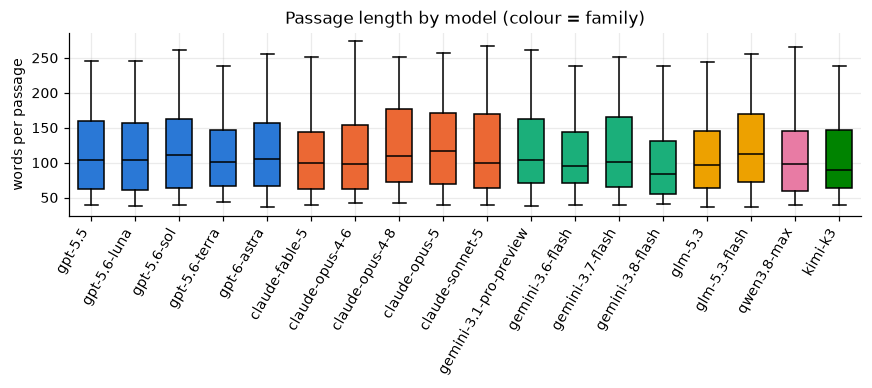

In [6]:
# Label counts and length distributions per class (full labelled data)
full = train_df.assign(family=train_df["model"].map(family),
                       n_chars=train_df["text"].str.len(),
                       n_words=train_df["text"].str.split().str.len())
counts = pd.DataFrame({"all": full["model"].value_counts(),
                       "train_split": d["model"].value_counts(),
                       "test_split": test_split_df["model"].value_counts()}).loc[CLASS_ORDER]
print("passages per class: min", counts["all"].min(), "max", counts["all"].max(), "| total", counts["all"].sum())
length_stats = full.groupby("model")[["n_chars", "n_words"]].describe().loc[CLASS_ORDER]
length_stats = length_stats.loc[:, (slice(None), ["mean", "50%", "std", "min", "max"])].round(0)
display(counts.T)
display(length_stats)

fig, ax = plt.subplots(figsize=(8, 3.6))
data = [full.loc[full["model"] == m, "n_words"] for m in CLASS_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "black"}, flierprops={"markersize": 3})
for patch, m in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(FAMILY_COLOR[family(m)])
ax.set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER, rotation=60, ha="right")
ax.set_ylabel("words per passage")
ax.set_title("Passage length by model (colour = family)")
fig.tight_layout(); fig.savefig(FIG_DIR / "s1_length_by_model.png", dpi=200); plt.show()

,newlines,md_headers,bullets,bold,em_dash,curly_quotes,straight_quotes,semicolons,colons,non_ascii
model,,,,,,,,,,
gpt-5.5,0.0,0.0,0.0,0.0,0.21,0.91,0.23,0.83,0.93,1.17
gpt-5.6-luna,0.0,0.0,0.0,0.0,0.49,1.11,0.02,0.57,0.99,1.69
gpt-5.6-sol,0.0,0.0,0.0,0.0,0.38,1.27,0.00,0.84,0.91,1.76
gpt-5.6-terra,0.0,0.0,0.0,0.0,0.37,0.91,0.05,0.64,0.94,1.41
gpt-6-astra,0.0,0.0,0.0,0.0,0.11,0.89,0.17,0.69,0.89,1.11
claude-fable-5,0.0,0.0,0.0,0.0,1.50,0.00,1.20,0.46,0.76,1.60
claude-opus-4-6,0.0,0.0,0.0,0.0,1.30,0.00,1.25,0.15,0.46,1.43
claude-opus-4-8,0.0,0.0,0.0,0.0,0.97,0.00,1.17,0.26,0.56,1.03
claude-opus-5,0.0,0.0,0.0,0.0,1.50,0.00,1.28,0.66,0.96,1.61


share of passages with >=1 occurrence:
 {'newlines': 0.0, 'md_headers': 0.0, 'bullets': 0.0, 'bold': 0.0, 'em_dash': 0.39, 'curly_quotes': 0.225, 'straight_quotes': 0.321, 'semicolons': 0.387, 'colons': 0.521, 'non_ascii': 0.578}


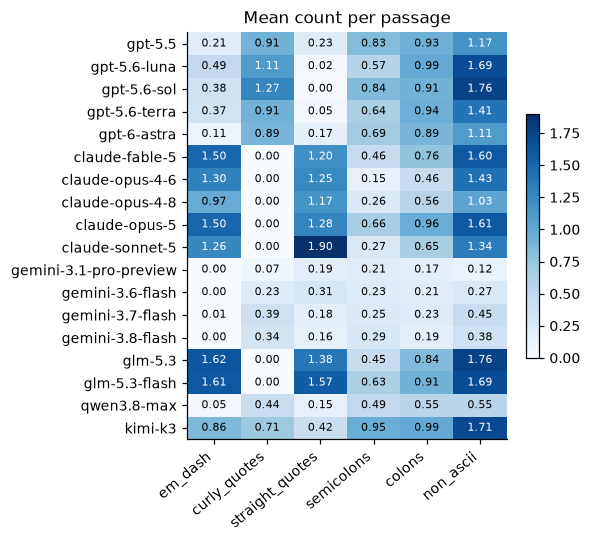

In [7]:
# Formatting / typography statistics per class (mean count per passage)
def formatting_features(texts: pd.Series) -> pd.DataFrame:
    return pd.DataFrame({
        "newlines": texts.str.count("\n"),
        "md_headers": texts.str.count(r"(?m)^#{1,6} "),
        "bullets": texts.str.count(r"(?m)^\s*(?:[-*•]|\d+\.)\s"),
        "bold": texts.str.count(r"\*\*[^*]+\*\*"),
        "em_dash": texts.str.count("—"),
        "curly_quotes": texts.str.count("[“”‘’]"),
        "straight_quotes": texts.str.count("[\"']"),
        "semicolons": texts.str.count(";"),
        "colons": texts.str.count(":"),
        "non_ascii": texts.apply(lambda s: sum(ord(c) > 127 for c in s)),
    })


fmt = formatting_features(full["text"]).assign(model=full["model"])
fmt_by_class = fmt.groupby("model").mean().loc[CLASS_ORDER].round(2)
display(fmt_by_class)
print("share of passages with >=1 occurrence:\n", (fmt.drop(columns="model") > 0).mean().round(3).to_dict())

cols = ["em_dash", "curly_quotes", "straight_quotes", "semicolons", "colons", "non_ascii"]
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(fmt_by_class[cols].to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
for i in range(len(CLASS_ORDER)):
    for j, c in enumerate(cols):
        v = fmt_by_class[c].iloc[i]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 1.0 else "black")
ax.grid(False); ax.set_title("Mean count per passage")
fig.colorbar(im, ax=ax, shrink=0.6); fig.tight_layout()
fig.savefig(FIG_DIR / "s1_typography_by_model.png", dpi=200); plt.show()

In [8]:
# Exact and near duplicates (char 3-5-gram TF-IDF cosine), and prompt overlap between splits
from sklearn.feature_extraction.text import TfidfVectorizer

texts = full["text"]
print("exact duplicate texts:", texts.duplicated().sum())
X_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(texts)
S = (X_char @ X_char.T).toarray()
np.fill_diagonal(S, 0)
print("max pairwise cosine:", S.max().round(3))
for th in (0.95, 0.9, 0.8):
    print(f"  pairs with cosine > {th}: {(np.triu(S) > th).sum()}")
i, j = np.unravel_index(S.argmax(), S.shape)
print(f"closest pair: {full.model[i]} vs {full.model[j]}, same prompt: {full.prompt_id[i] == full.prompt_id[j]}")
del S

print("\ncolumns train.csv:", list(train_df.columns), "| test.csv:", list(test_df.columns))
print("prompts shared between Kazik's train and test split:",
      len(set(d["prompt_id"]) & set(test_split_df["prompt_id"])))
print("passages per prompt:", train_df.groupby("prompt_id").size().value_counts().to_dict())
print("NFC changes", (texts != texts.map(lambda s: unicodedata.normalize("NFC", s))).sum(),
      "texts; NFKC would change", (texts != texts.map(lambda s: unicodedata.normalize("NFKC", s))).sum())

exact duplicate texts: 0


max pairwise cosine: 0.691
  pairs with cosine > 0.95: 0
  pairs with cosine > 0.9: 0
  pairs with cosine > 0.8: 0
closest pair: claude-fable-5 vs claude-opus-4-8, same prompt: True

columns train.csv: ['id', 'prompt_id', 'text', 'model', 'n_chars', 'n_words'] | test.csv: ['id', 'text']
prompts shared between Kazik's train and test split: 0
passages per prompt: {18: 149, 17: 1}
NFC changes 0 texts; NFKC would change 12


**Findings (step 1)**

- **Labels:** 18 classes, 149–150 passages each (2,699 in total; `claude-fable-5` has 149). Kazik's split: 2,159 train / 540 test, 120 vs 30 prompts, 30 test passages per class.
- **Prompt column:** `prompt_id` exists. Every prompt is answered by all 18 models (one by 17), so the topic carries no label information, but passages answering the same prompt are correlated. Kaggle states that test prompts never appear in `train.csv`, so Kazik's prompt-grouped split and our grouped folds (step 2) match the competition setting. 0 prompts are shared between our splits.
- **Length:** the means range from 101 words (gemini-3.8-flash) to 124 (claude-opus-4-8), but within-class spread is much larger (Kaggle: lengths "vary randomly between 40 and 250 words"). The length-only baseline in step 2 checks how much this helps.
- **Formatting:** no newlines, markdown headers, bullets or bold anywhere: every passage is a single plain paragraph. The markdown cue reported by Sun et al. (2025) is therefore absent. Typography is very informative at the **family** level: Claude and GLM never use curly quotes; GPT uses curly quotes and almost no straight ones; Gemini almost never uses em dashes; Claude and GLM use more than one em dash per passage.
- **Duplicates:** no exact duplicates; the highest char-n-gram cosine is 0.69 (two answers to the same prompt), so there are no near-duplicates to remove.
- **Metric:** the Kaggle metric is **balanced accuracy** (mean per-class recall). The hidden test set (~4,000 passages) is not class-balanced, so we use balanced accuracy as the primary metric.
- **Confound (no action):** Claude models launched from August 2026 bias token sampling with a watermark, and Gemini API text may carry SynthID; GPT API watermarking is off by default. We cannot detect these without the providers' keys, but they may shift token statistics that our classifiers pick up.
- Token counts per tokeniser are reported in step 4, once the tokenisers are fixed.

## Step 2 · Evaluation protocol (fixed before any model is trained)

**Why:** every comparison (ours and Liam's) has to use the same folds, metric, tuning rule and statistical test, otherwise the numbers can't be compared. All of it lives in `shared/eval_harness.py`.

- **Folds:** `StratifiedGroupKFold(5)` grouped by `prompt_id`, on Kazik's train split only. Grouping is required because test prompts are unseen (Kaggle) and passages for the same prompt share content. Repeated **R = 10** times (different shuffles, seeds 42–51) for cheap models; the fine-tuned model (step 6.5) uses **R = 1** (5 folds), because one fine-tuning fold costs minutes, not seconds. Indices are saved in `shared/folds.json` (by passage `id`); Kazik, Liam and we all load this file.
- **Metric:** balanced accuracy (Kaggle) is primary; accuracy and macro-F1 are also reported. With grouped folds each validation fold has 431–432 passages, about 24 per class.
- **Tuning: nested.** Inside each outer training fold, 20% of its prompts are held out (grouped) as the inner validation set. The grid point with the best inner balanced accuracy is refit on the full outer training fold and scored once on the outer fold. The MLPs use the same inner set for early stopping and are refit for the selected number of epochs. Because the outer fold is never used for selection, the reported scores aren't inflated by tuning.
- **Bayesian comparison:** Bayesian correlated t-test (Benavoli et al., 2017) on paired per-fold scores, with ρ = n_test / n_total = 432 / 2,159 ≈ 0.20, computed from the folds. Our implementation matches `baycomp.two_on_single` exactly (checked below).
- **ROPE = 1 percentage point of balanced accuracy.** That is about 4 passages per 432-passage fold. Differences below this are not practically meaningful for us: (i) the binomial standard error of a single test-set score at about 70% accuracy is √(0.7·0.3/540) ≈ 2 pp on our 540-passage test split, so a < 1 pp difference couldn't be confirmed on held-out data anyway; (ii) on Kaggle's ~4,000 passages, 1 pp is about 40 passages, which is roughly the gap between neighbouring leaderboard positions we would care about. (The brief estimated 540 passages per fold, which is the size of the test split; the CV folds hold 432.)
- **Test split:** used once, in step 7.

In [9]:
# Build (once) and load the shared folds
R_CHEAP, R_FINETUNE = 10, 1
if not H.FOLDS_PATH.exists():
    H.save_folds(H.make_folds(d["id"], y, groups, repeats=R_CHEAP))
FOLDS = H.load_folds(d["id"].tolist())                          # 10 x 5 = 50 folds
FOLDS_FT = H.load_folds(d["id"].tolist(), repeats=R_FINETUNE)   # first repeat only
for r, k, tr, te in FOLDS:
    assert set(groups[tr]).isdisjoint(groups[te])
print(len(FOLDS), "folds | test sizes", sorted({len(te) for *_, te in FOLDS}),
      "| rho =", round(np.mean([len(te) / (len(tr) + len(te)) for *_, tr, te in FOLDS]), 4))

50 folds | test sizes [431, 432] | rho = 0.2


In [10]:
# Baselines on the protocol: majority class and length-only logistic regression
import baycomp

maj = pd.DataFrame([H.scores(y[te], np.full(len(te), np.bincount(y[tr]).argmax())) for *_, tr, te in FOLDS])


def length_features(texts: pd.Series) -> np.ndarray:
    L = np.c_[texts.str.len(), texts.str.split().str.len(), texts.str.count(r"[.!?](?:\s|$)")]
    return np.c_[L, np.log1p(L)]


X_len = length_features(d["text"])
RESULTS = {}  # name -> run_cv result; every model/representation lands here
RESULTS["length/logreg"] = H.run_cv(X_len, y, groups, FOLDS, "logreg")
display(pd.DataFrame({"majority": maj.mean(),
                      "length/logreg": pd.DataFrame(RESULTS["length/logreg"]["folds"])[list(maj)].mean()}).T.round(4))

# Cross-check our correlated t-test against baycomp (rho = 1/5 for 5-fold CV)
ovr = H.run_cv(X_len, y, groups, FOLDS, "logreg_ovr", verbose=False)
a, b = H.fold_scores(RESULTS["length/logreg"]), H.fold_scores(ovr)
ours = H.correlated_ttest(a, b, rho=0.2)
print("ours   :", np.round([ours["p_a_better"], ours["p_rope"], ours["p_b_better"]], 4))
print("baycomp:", np.round(baycomp.two_on_single(a, b, rope=H.ROPE, runs=R_CHEAP), 4))

logreg       bal.acc 0.1195 ± 0.0136  (50 folds, 2s)


,balanced_accuracy,accuracy,macro_f1
majority,0.0556,0.0551,0.0058
length/logreg,0.1195,0.1195,0.0891


ours   : [0.9801 0.0198 0.    ]
baycomp: [0.9801 0.0198 0.    ]


**Findings (step 2):** chance is 1/18 = 5.6% balanced accuracy. Length features alone reach about 12%: above chance but weak, which is consistent with the organisers randomising passage length. Length is not a shortcut here, and any model far above 12% is using something other than length. Our correlated t-test reproduces `baycomp` exactly.

### Reflections — Step 1

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._
**Rubric / oral-assessment points** (slide: _data and metrics_):
- How many classes, how many examples per class? Is it balanced, and what does that imply for the metric (accuracy vs. macro-F1)?
- What is `prompt_id`? The same prompt is answered by several models, so folds should be grouped by prompt to avoid leakage (see Step 5).
- Text length per model: could a classifier "cheat" on length alone?
- Which models are near-duplicates (same family, e.g. `gemini-3.x-flash`, `gpt-5.6-*`)? Expect confusions there.
- `test.csv` only has a handful of rows (the real Kaggle test set is hidden), so all evaluation is via cross-validation on `train.csv`.

1. 18 classes, 150 instances per class, balanced. This implies that (balanced) accuracy would be a good metric to use.
2. we are going to stratify the folds by prompt_id, so that we don't have leakage between train and test sets (120-30 split). This is important because the same prompt can be answered by different models, and we don't want to have the same prompt in both train and test sets. On the training set we are going to perform a 5/10-fold ?? cross-validation, and then we are going to evaluate the best model on the test set.
3. Test statistical significance of mean + median (rule out outliers) length/n of chars to see if there is significance the model could deploy in classification (how do we counter this?), do we need to counter it? length could just be one feature 

compute distribution over the vocab 

## 2. Tokenisation

**What they ask:** to build any classifier we need a way to segment text. Do we reuse the tutorial's tokeniser, or train a new one? If new, with which hyperparameters (vocab size, min frequency, pre-tokeniser), and on which data? Our dataset may be too small to train a tokeniser, so would a larger resource of similar nature be needed?

**Rubric / oral-assessment points** (slide: _features_; tutorial questions may come up too):
- Why BPE (subwords) vs. whitespace / character tokenisation for _authorship_ of LLM text? Punctuation, formatting and casing may carry the stylistic signal, so should we keep them?
- Vocab size trade-off: larger vocabularies give more specific features but sparser counts on ~2.7k documents.
- Training data for the tokeniser: train on all of `train.csv` (risk: it sees validation folds), only on the training folds, or an external corpus? Justify the choice.
- Unknown tokens / coverage: what fraction of tokens become `[UNK]`?

Helpers: `part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)`, `part1.bpe` (tutorial's BPE).

In [11]:
set_seed(SEEDS[0])

# TODO: choose tokeniser + hyperparameters
# tokenizer = part1.experiment.train_tokenizer(corpus=train_df["text"].tolist(), vocab_size=..., min_frequency=...)
# print(tokenizer.get_vocab_size())
# print(tokenizer.encode(train_df["text"][0]).tokens[:50])

## Step 3 · Preprocessing

**Why:** punctuation, casing and typography are the authorship signal (step 1: quotes and em dashes separate families), so we change as little as possible: NFC normalisation only, with no lowercasing and no stopword or punctuation removal.

In [12]:
from shared.tokenization import preprocess  # NFC only; shared with Kazik and Liam

nfkc_changed = full["text"][full["text"] != full["text"].map(lambda s: unicodedata.normalize("NFKC", s))]
nfkc_chars = sorted({c for s in nfkc_changed for c in s if unicodedata.normalize("NFKC", c) != c})
print("NFC changes:", (full["text"] != full["text"].map(preprocess)).sum(), "texts")
print("NFKC would change", len(nfkc_changed), "texts; affected characters:", nfkc_chars)
print("texts with newlines:", full["text"].str.contains("\n").sum(),
      "| double spaces:", full["text"].str.contains("  ").sum(),
      "| leading/trailing whitespace:", (full["text"] != full["text"].str.strip()).sum())

NFC changes: 0 texts
NFKC would change 12 texts; affected characters: ['²', '³', '⁵', '⁶', '⁷', '⁺', '⁻', '₀', '₂']
texts with newlines: 0 | double spaces: 0 | leading/trailing whitespace: 0


**Findings (step 3):** NFC is a no-op on this data; NFKC would have changed 12 texts (superscripts and similar), so we keep NFC. No passage contains a newline (step 1), so the planned CV test of an explicit `\n` marker for tokenisers that drop newlines has nothing to act on, and we skip it. Whitespace handling is checked per tokeniser in step 4.

## Step 4 · Tokenisation (hand-off to Kazik)

**Why:** pretrained models must use their own tokeniser (their embeddings are indexed by it), so there is no choice to make for them. The only choice is for the from-scratch transformer, and we measure what each tokeniser keeps of the typography cues.

- **Pretrained:** LUSR → RoBERTa byte-level BPE; Qwen3-Embedding-0.6B and Qwen3-0.6B-Base → Qwen byte-level BPE; fine-tuning candidates ModernBERT-base (BPE) and DeBERTa-v3-base (SentencePiece).
- **From-scratch transformer (provisional, Kazik decides):** we reuse the pretrained RoBERTa BPE vocabulary, restricted to tokens seen at least twice in the training fold (all others map to `<unk>`). Our train split has about 330k tokens, far too few to learn good merges, and the tutorial tokeniser (BPE, 1k vocabulary, trained on AG News) is shown below to map typography cues to `[UNK]`.
- `shared/tokenization.py`: `tokenize(texts, tokenizer_name)` returns token-id lists; `tokenizer_stats` gives fertility (tokens per whitespace word), the share of documents truncated at 512 tokens, the unknown-token rate, and whether typography and whitespace survive a round trip.

In [13]:
# tokenize(), tokenizer_stats() and the TOKENIZERS registry live in shared/tokenization.py (hand-off to Kazik)
from shared.tokenization import CACHE_DIR, TOKENIZERS, get_tokenizer, tokenize, tokenizer_stats

CACHE_DIR.mkdir(exist_ok=True)
print(TOKENIZERS)
TOK_STATS = tokenizer_stats(full["text"])
with pd.option_context("display.max_colwidth", 60, "display.width", 200):
    display(TOK_STATS.round(4))

# Token length per class under the tokenisers our embedders use (step 1 asked for this)
tok_len = pd.DataFrame({n: [len(x) for x in tokenize(full["text"], n)] for n in ["roberta-bpe", "qwen3-bpe"]})
display(tok_len.assign(model=full["model"]).groupby("model").agg(["mean", "max"]).loc[CLASS_ORDER].round(1))

{'roberta-bpe': 'rrivera1849/LUSR', 'qwen3-bpe': 'Qwen/Qwen3-Embedding-0.6B', 'modernbert': 'answerdotai/ModernBERT-base', 'deberta-v3': 'microsoft/deberta-v3-base', 'tutorial-bpe-1k': 'tutorial'}


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


,vocab,fertility,mean_tokens,max_tokens,truncated@512,unk_rate,docs_with_unk,probe_roundtrip
tokenizer,,,,,,,,
roberta-bpe,50265,1.2905,147.9641,385,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
qwen3-bpe,151669,1.2803,146.8007,381,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
modernbert,50368,1.3048,149.6117,394,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
deberta-v3,128001,1.2117,138.9344,349,0.000,0.0001,0.0044,He said “no” — it’s 5 [UNK]m[UNK] done
tutorial-bpe-1k,1000,2.7073,310.4202,769,0.136,0.0038,0.5824,He said [UNK]no[UNK] [UNK] it[UNK]s 5 [UNK]m[UNK] done


roberta-bpe      qwen3-bpe     
                              mean  max      mean  max
model                                                 
gpt-5.5                      143.7  311     141.3  307
gpt-5.6-luna                 148.4  303     145.8  296
gpt-5.6-sol                  153.4  330     150.5  320
gpt-5.6-terra                146.6  325     144.1  317
gpt-6-astra                  145.3  302     143.7  303
claude-fable-5               146.9  333     146.2  332
claude-opus-4-6              147.0  328     146.6  336
claude-opus-4-8              159.2  320     158.6  320
claude-opus-5                158.2  360     157.5  344
claude-sonnet-5              158.7  385     157.5  381
gemini-3.1-pro-preview       148.2  317     148.6  326
gemini-3.6-flash             140.9  305     140.6  308
gemini-3.7-flash             151.7  349     151.0  347
gemini-3.8-flash             132.4  313     132.1  319
glm-5.3                      144.8  327     144.1  329
glm-5.3-flash                155.9  334     155.5  332
qwen3.8-max                  140.1  335     138.6  332
kimi-k3                      141.8  314     140.0  315

**Findings (step 4):**
- **Byte-level BPEs (RoBERTa, Qwen3, ModernBERT):** curly quotes, em dashes, "µ" and "…" round-trip exactly, with 0 unknown tokens. Fertility is about 1.3 tokens per word, and the longest passage has under 400 tokens, so **nothing is truncated at 512** and chunking (step 5) never triggers for 512-token models.
- **DeBERTa-v3:** maps "µ" and "…" to `[UNK]` (0.4% of documents) and collapses double spaces. The data has no double spaces (step 3), so only the `[UNK]` loss matters.
- **Tutorial 1k BPE (AG News):** maps curly quotes, em dashes and apostrophes to `[UNK]` in **58% of passages**, exactly the family cues from step 1. It also has 2.7 tokens per word, so 14% of passages would be truncated at 512. This confirms that the from-scratch transformer should reuse the RoBERTa vocabulary instead.
- **Token length per class:** class means are 132–159 tokens, the same ordering as the word counts in step 1.

### Reflections — Step 2

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._

-

## 3. Document representations (features)

**What they ask:** think about how to turn documents into features. The tutorial used token occurrences (indicators) and frequencies (bag-of-words). Can we think of other ways?

**Rubric (checklist):** compare **the two representation spaces from the tutorial (token indicators and bag-of-words) plus one more of our choice**.

**Oral-assessment points** (slide: _features_):
- What does each representation capture, and what does it throw away (order, length, frequency)?
- Candidates for the third representation: TF-IDF, character n-grams, word n-grams, stylometric features (sentence length, punctuation rates, markdown usage), or combinations. Why this one for _LLM authorship_?
- Dimensionality / sparsity, and how the choice interacts with the classifier.

Helpers: `part1.clslib.TokenIndicator` (indicator encoder); bag-of-words and the third encoder are ours to write as `part1.clslib.Encoder` subclasses.

In [14]:
# TODO: define the three encoders
# indicator_enc = part1.clslib.TokenIndicator(tokenizer)
#
# class BagOfWords(part1.clslib.Encoder):
#     ...
#
# class OurThirdEncoder(part1.clslib.Encoder):
#     ...

### Reflections — Step 3

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._

-

## 4. Architectures

**What they ask:** the tutorial used logistic regression (log-linear) and a shallow neural network. Experiment with different architectures and their hyperparameters (e.g. more layers, different activation functions, dropout rates).

**Rubric (checklist):** compare **log-linear, single-hidden-layer MLP, plus one more architecture of our choice** (e.g. a modification of the MLP).

**Oral-assessment points** (slide: _architectures_):
- What does the MLP add over the log-linear model, and does this dataset size (~2.7k docs, ~18 classes) support it?
- Why our third architecture, and what hypothesis does it test?
- Which hyperparameters did we tune, how (on what data, to avoid tuning on the evaluation folds), and why those values?

Helpers: `part1.loglin.fit`, `part1.smlp.SparseMLP`, `part1.smlp.train_neural_network_model`, `part1.experiment.cross_validation_experiment(..., model_option="logistic" | "mlp")`.

In [15]:
# TODO: architectures + hyperparameters
# LOGLIN_ARGS = dict(max_iter=100)
# SMLP_ARGS = dict(hidden_dim=128, dropout=0.1, num_epochs=20, learning_rate=1e-3)
#
# class OurThirdModel(torch.nn.Module):
#     ...

### Reflections — Step 4

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._

-

## 5. Evaluation

**What they ask:** evaluate the models. Was the evaluation method adequate for our new experimental setup? Do we want to assess other aspects of performance?

**Rubric (checklist):** comparisons must be **based on cross-validation and a relevant metric** (accuracy or other).

**Oral-assessment points** (slide: _data and metrics_ / _results_):
- Is accuracy appropriate here (balanced classes?) or should we also report macro-F1 / per-class F1 / confusion matrix?
- **Leakage:** `cross_validation_split` shuffles texts at random, so answers to the same prompt land in both train and validation. Do we need grouped folds by `prompt_id`? Compare both and explain the difference.
- How many folds and seeds, and why? (Here: `NUM_FOLDS` folds × `SEEDS`.)
- Other aspects: training/inference time, calibration, which models get confused with each other.

In [16]:
from collections import OrderedDict

# One entry per system, e.g. "logistic_indicator" -> list over seeds of cross_validation_experiment results
results = OrderedDict()


def run_cv(name, encoder, model_option, **kwargs):
    """Run k-fold CV once per seed, seeding right before each split + training run."""
    results[name] = []
    for seed in SEEDS:
        set_seed(seed)
        splits = part1.experiment.cross_validation_split(pairs, k=NUM_FOLDS, seed=seed)
        set_seed(seed)
        res = part1.experiment.cross_validation_experiment(
            splits, outcome_space, encoder, model_option,
            save_to=str(RESULTS_DIR / name / f"seed-{seed}"), **kwargs,
        )
        results[name].append(res)
    per_seed = [np.mean(list(r["accuracies"].values())) for r in results[name]]
    mean, ci = summarise_runs(per_seed)
    print(f"{name}: acc {mean:.4f}  95% CI {ci}")


# TODO: e.g.
# run_cv("logistic_indicator", indicator_enc, "logistic", loglin_args=LOGLIN_ARGS)
# run_cv("mlp_indicator", indicator_enc, "mlp", smlp_args=SMLP_ARGS)

### Reflections — Step 5

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._

-

## 6. Analysis: which system is best?

**What they ask:** analyse the models we assessed and decide which is best.

**Rubric (checklist):** use **Bayesian estimation to analyse results relative to a region of practical equivalence (ROPE)**, and **motivate the ROPE size** ourselves.

**Oral-assessment points** (slide: _results_, plus _extra_):
- What do P(A better), P(equivalent), P(B better) mean, and how do they depend on the ROPE?
- Why our ROPE size (e.g. what accuracy difference would matter in practice for this task)?
- Is the best system clearly better, or practically equivalent to a simpler one? If equivalent, which would we pick and why?
- Error analysis: which LLMs get confused (confusion matrix), and do the errors make sense (same family / provider)?
- Extra slide ideas: grouped-vs-random folds, ensembles, feature inspection (most predictive tokens per model).

Helpers: `part1.analysis.make_data_frame`, `plot_box_and_points`, `BenavoliCorrelatedT(sys_a, sys_b, runs=len(SEEDS)).plot(rope)` / `.probs(rope)`.

In [17]:
# TODO: compare systems
# df = part1.analysis.make_data_frame(...)
# part1.analysis.plot_box_and_points(df, metric="accuracy")
#
# ROPE = 0.01  # motivate this!
# cmp = part1.analysis.BenavoliCorrelatedT(sys_a_scores, sys_b_scores, runs=len(SEEDS), names=["A", "B"])
# cmp.plot(ROPE); print(cmp.probs(ROPE))

### Reflections — Step 6

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._

-

## AI-assistance & sources log

We must disclose this in the blog post. Keep a running list: what was delegated to an assistant, and which external sources/code were used.

| Date | Who | Tool / source | What for |
|---|---|---|---|
| 2026-11-02 | Cecce | Claude Code | Notebook skeleton (this structure + reproducibility cell) |